In [1]:
import pandas as pd
import numpy as np

df = pd.read_csv("../data/doctor_visits_cleaned.csv")

print(df.shape)
df.head()

(5190, 14)


,Unnamed: 0,visits,gender,age,income,illness,reduced,health,private,freepoor,freerepat,nchronic,lchronic,age_group
0,1,1,female,0.19,0.55,1,4,1,yes,no,no,no,no,0-18
1,2,1,female,0.19,0.45,1,2,1,yes,no,no,no,no,0-18
2,3,1,male,0.19,0.90,3,0,0,no,no,no,no,no,0-18
3,4,1,male,0.19,0.15,1,0,0,no,no,no,no,no,0-18
4,5,1,male,0.19,0.45,2,5,1,no,no,no,yes,no,0-18


In [2]:
print(df["visits"].describe())
print("\nVisit Frequency:")
print(df["visits"].value_counts().sort_index())

count    5190.000000
mean        0.301734
std         0.798134
min         0.000000
25%         0.000000
50%         0.000000
75%         0.000000
max         9.000000
Name: visits, dtype: float64

Visit Frequency:
visits
0    4141
1     782
2     174
3      30
4      24
5       9
6      12
7      12
8       5
9       1
Name: count, dtype: int64


In [3]:
df["frequent_visitor"] = np.where(
    df["visits"] >= 2,
    1,
    0
)

print("Frequent Visitor Distribution:")
print(df["frequent_visitor"].value_counts())

print("\nPercentage Distribution:")
print(
    df["frequent_visitor"]
    .value_counts(normalize=True)
    .mul(100).round(2)
)

Frequent Visitor Distribution:
frequent_visitor
0    4923
1     267
Name: count, dtype: int64

Percentage Distribution:
frequent_visitor
0    94.86
1     5.14
Name: proportion, dtype: float64


In [11]:
from sklearn.preprocessing import LabelEncoder

features = [
    "gender",
    "age",
    "income",
    "illness",
    "reduced",
    "health",
    "private",
    "freepoor",
    "freerepat",
    "nchronic",
    "lchronic"
]

X = df[features].copy()
y = df["frequent_visitor"]

categorical_columns = X.select_dtypes(include=["object", "category"]).columns

for column in categorical_columns:
    encoder = LabelEncoder()
    X[column] = encoder.fit_transform(X[column].astype(str))

print("Categorical columns encoded:", list(categorical_columns))
print("\nFeature data types:")
print(X.dtypes)

print("\nX shape:", X.shape)
print("y shape:", y.shape)

Categorical columns encoded: ['gender', 'private', 'freepoor', 'freerepat', 'nchronic', 'lchronic']

Feature data types:
gender         int64
age          float64
income       float64
illness        int64
reduced        int64
health         int64
private        int64
freepoor       int64
freerepat      int64
nchronic       int64
lchronic       int64
dtype: object

X shape: (5190, 11)
y shape: (5190,)


C:\Users\anusr\AppData\Local\Temp\ipykernel_16440\917606539.py:20: Pandas4Warning: For backward compatibility, 'str' dtypes are included by select_dtypes when 'object' dtype is specified. This behavior is deprecated and will be removed in a future version. Explicitly pass 'str' to `include` to select them, or to `exclude` to remove them and silence this warning.
See https://pandas.pydata.org/docs/user_guide/migration-3-strings.html#string-migration-select-dtypes for details on how to write code that works with pandas 2 and 3.
  categorical_columns = X.select_dtypes(include=["object", "category"]).columns


In [7]:
%pip install scikit-learn

  Using cached scipy-1.18.1-cp314-cp314-win_amd64.whl.metadata (61 kB)
  Using cached joblib-1.6.0-py3-none-any.whl.metadata (6.5 kB)
  Using cached threadpoolctl-3.7.0-py3-none-any.whl.metadata (24 kB)
  Using cached cloudpickle-3.1.2-py3-none-any.whl.metadata (7.1 kB)
   ---------------------------------------- 0.0/8.4 MB ? eta -:--:--
   ---------------------------------------- 0.0/8.4 MB ? eta -:--:--
   -- ------------------------------------- 0.5/8.4 MB 1.4 MB/s eta 0:00:06
   -- ------------------------------------- 0.5/8.4 MB 1.4 MB/s eta 0:00:06
   ----- ---------------------------------- 1.0/8.4 MB 1.4 MB/s eta 0:00:06
   ------- -------------------------------- 1.6/8.4 MB 1.6 MB/s eta 0:00:05
   ---------- ----------------------------- 2.1/8.4 MB 1.8 MB/s eta 0:00:04
   ------------ --------------------------- 2.6/8.4 MB 1.9 MB/s eta 0:00:04
   ------------ --------------------------- 2.6/8.4 MB 1.9 MB/s eta 0:00:04
   ------------- -------------------------- 2.9/8.4 MB 1.7 


[notice] A new release of pip is available: 25.2 -> 26.2.1
[notice] To update, run: python.exe -m pip install --upgrade pip


In [12]:
from sklearn.model_selection import train_test_split

X_train, X_test, y_train, y_test = train_test_split(
    X,
    y,
    test_size=0.20,
    random_state=42,
    stratify=y
)

print("Training data:", X_train.shape)
print("Testing data:", X_test.shape)

print("\nTraining target distribution:")
print(y_train.value_counts())

print("\nTesting target distribution:")
print(y_test.value_counts())

Training data: (4152, 11)
Testing data: (1038, 11)

Training target distribution:
frequent_visitor
0    3938
1     214
Name: count, dtype: int64

Testing target distribution:
frequent_visitor
0    985
1     53
Name: count, dtype: int64


In [13]:
from sklearn.linear_model import LogisticRegression
from sklearn.tree import DecisionTreeClassifier
from sklearn.ensemble import RandomForestClassifier

models = {
    "Logistic Regression": LogisticRegression(
        max_iter=1000,
        class_weight="balanced"
    ),
    "Decision Tree": DecisionTreeClassifier(
        max_depth=5,
        random_state=42,
        class_weight="balanced"
    ),
    "Random Forest": RandomForestClassifier(
        n_estimators=100,
        max_depth=8,
        random_state=42,
        class_weight="balanced"
    )
}

for name, model in models.items():
    model.fit(X_train, y_train)
    print(name, "trained successfully")

Logistic Regression trained successfully
Decision Tree trained successfully
Random Forest trained successfully


In [14]:
from sklearn.metrics import accuracy_score, precision_score, recall_score, f1_score

results = []

for name, model in models.items():
    y_pred = model.predict(X_test)

    results.append([
        name,
        accuracy_score(y_test, y_pred),
        precision_score(y_test, y_pred, zero_division=0),
        recall_score(y_test, y_pred, zero_division=0),
        f1_score(y_test, y_pred, zero_division=0)
    ])

model_results = pd.DataFrame(
    results,
    columns=[
        "Model",
        "Accuracy",
        "Precision",
        "Recall",
        "F1_Score"
    ]
)

model_results = model_results.sort_values(
    "F1_Score",
    ascending=False
).reset_index(drop=True)

model_results

,Model,Accuracy,Precision,Recall,F1_Score
0,Decision Tree,0.843931,0.181287,0.584906,0.276786
1,Logistic Regression,0.813102,0.169014,0.679245,0.270677
2,Random Forest,0.866089,0.183824,0.471698,0.264550


In [15]:
import os

os.makedirs("../reports", exist_ok=True)

model_results.to_csv(
    "../reports/model_comparison.csv",
    index=False
)

print("Model comparison saved successfully.")

Model comparison saved successfully.


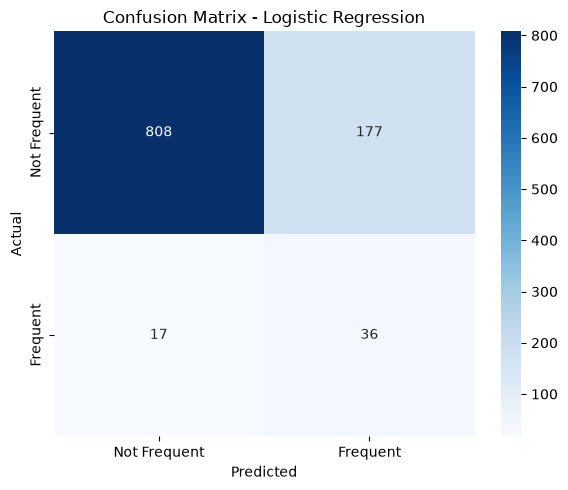

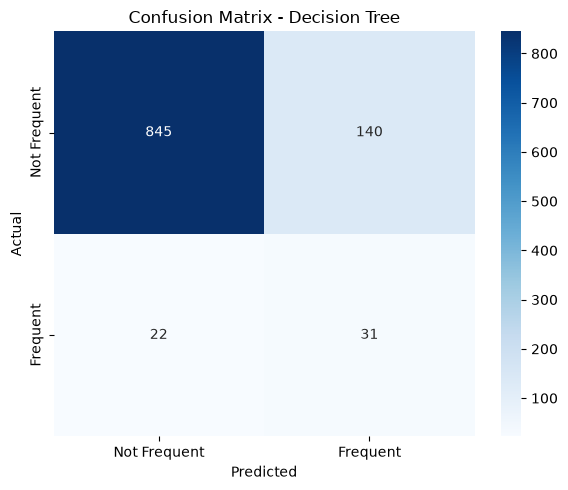

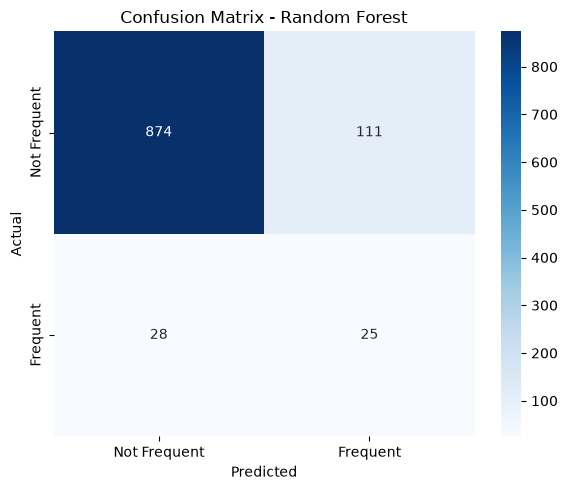

In [16]:
from sklearn.metrics import confusion_matrix
import matplotlib.pyplot as plt
import seaborn as sns

for name, model in models.items():
    y_pred = model.predict(X_test)
    cm = confusion_matrix(y_test, y_pred)

    plt.figure(figsize=(6, 5))
    sns.heatmap(
        cm,
        annot=True,
        fmt="d",
        cmap="Blues",
        xticklabels=["Not Frequent", "Frequent"],
        yticklabels=["Not Frequent", "Frequent"]
    )
    plt.title(f"Confusion Matrix - {name}")
    plt.xlabel("Predicted")
    plt.ylabel("Actual")
    plt.tight_layout()
    plt.show()

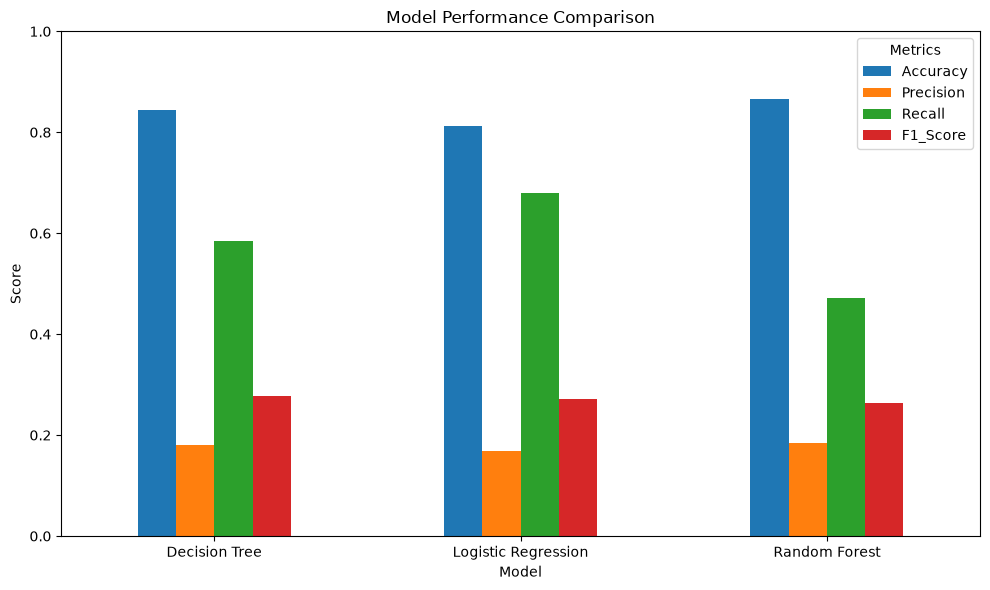

In [17]:
model_results_plot = model_results.set_index("Model")[
    ["Accuracy", "Precision", "Recall", "F1_Score"]
]

model_results_plot.plot(
    kind="bar",
    figsize=(10, 6)
)

plt.title("Model Performance Comparison")
plt.xlabel("Model")
plt.ylabel("Score")
plt.ylim(0, 1)
plt.xticks(rotation=0)
plt.legend(title="Metrics")
plt.tight_layout()
plt.show()

In [18]:
best_model_name = model_results.iloc[0]["Model"]

print("Best Model:", best_model_name)

print("\nBest Model Performance:")
print(model_results.iloc[0])

Best Model: Decision Tree

Best Model Performance:
Model        Decision Tree
Accuracy          0.843931
Precision         0.181287
Recall            0.584906
F1_Score          0.276786
Name: 0, dtype: object


In [19]:
rf_model = models["Random Forest"]

feature_importance = pd.DataFrame({
    "Feature": X.columns,
    "Importance": rf_model.feature_importances_
})

feature_importance = feature_importance.sort_values(
    "Importance",
    ascending=False
)

print(feature_importance)

      Feature  Importance
4     reduced    0.371234
3     illness    0.196750
5      health    0.107865
2      income    0.103367
1         age    0.088615
0      gender    0.030416
10   lchronic    0.029208
9    nchronic    0.024714
6     private    0.024265
8   freerepat    0.014148
7    freepoor    0.009420


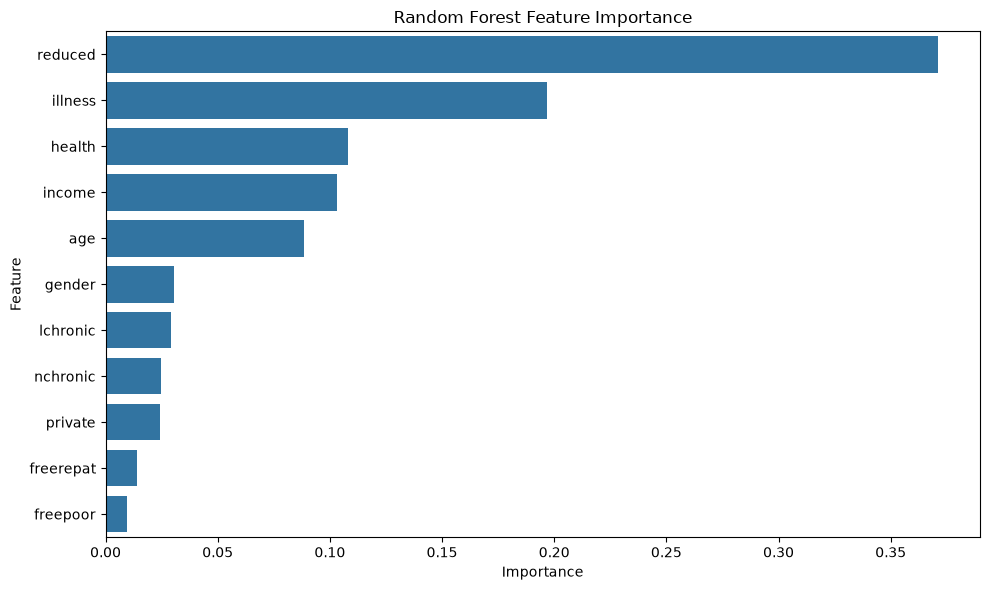

In [20]:
plt.figure(figsize=(10, 6))

sns.barplot(
    data=feature_importance,
    x="Importance",
    y="Feature"
)

plt.title("Random Forest Feature Importance")
plt.xlabel("Importance")
plt.ylabel("Feature")
plt.tight_layout()
plt.show()

In [21]:
import os

os.makedirs("../charts", exist_ok=True)
os.makedirs("../reports", exist_ok=True)
os.makedirs("../models", exist_ok=True)

print("Project folders ready.")

Project folders ready.


In [22]:
model_results.to_csv(
    "../reports/model_comparison.csv",
    index=False
)

print("Model comparison saved.")

Model comparison saved.


In [23]:
feature_importance.to_csv(
    "../reports/feature_importance.csv",
    index=False
)

print("Feature importance saved.")

Feature importance saved.


In [24]:
best_model = models[best_model_name]

y_pred = best_model.predict(X_test)

predictions = pd.DataFrame({
    "Actual": y_test.values,
    "Predicted": y_pred
})

predictions.to_csv(
    "../reports/model_predictions.csv",
    index=False
)

print("Predictions saved.")

Predictions saved.


In [25]:
import joblib

joblib.dump(
    best_model,
    "../models/best_model.pkl"
)

print("Best model saved successfully.")

Best model saved successfully.


<Figure size 1000x600 with 0 Axes>

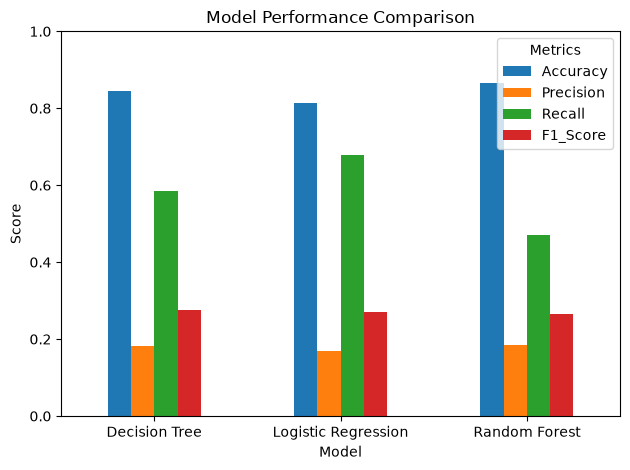

In [26]:
plt.figure(figsize=(10, 6))

model_results_plot.plot(
    kind="bar"
)

plt.title("Model Performance Comparison")
plt.xlabel("Model")
plt.ylabel("Score")
plt.ylim(0, 1)
plt.xticks(rotation=0)
plt.legend(title="Metrics")
plt.tight_layout()

plt.savefig(
    "../charts/model_performance_comparison.png",
    dpi=300,
    bbox_inches="tight"
)

plt.show()

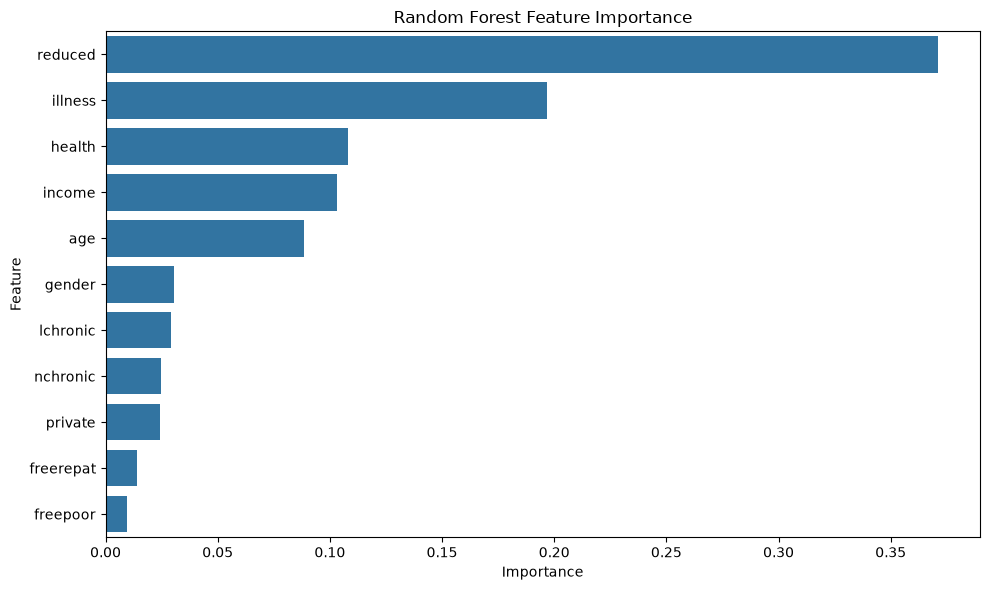

In [27]:
plt.figure(figsize=(10, 6))

sns.barplot(
    data=feature_importance,
    x="Importance",
    y="Feature"
)

plt.title("Random Forest Feature Importance")
plt.xlabel("Importance")
plt.ylabel("Feature")
plt.tight_layout()

plt.savefig(
    "../charts/random_forest_feature_importance.png",
    dpi=300,
    bbox_inches="tight"
)

plt.show()

In [28]:
insights = []

total_patients = len(df)
zero_visit_patients = (df["visits"] == 0).sum()
frequent_visitors = (df["visits"] >= 2).sum()

zero_visit_percentage = zero_visit_patients / total_patients * 100
frequent_visitor_percentage = frequent_visitors / total_patients * 100

insights.append([
    "Total Patients",
    total_patients,
    "Total number of records analyzed"
])

insights.append([
    "Average Doctor Visits",
    round(df["visits"].mean(), 2),
    "Average number of doctor visits per patient"
])

insights.append([
    "Patients With Zero Visits",
    zero_visit_percentage,
    "Percentage of patients with no recorded doctor visits"
])

insights.append([
    "Frequent Visitors",
    frequent_visitor_percentage,
    "Percentage of patients with two or more doctor visits"
])

insights.append([
    "Maximum Doctor Visits",
    df["visits"].max(),
    "Highest number of recorded doctor visits"
])

insights.append([
    "Best Predictive Model",
    best_model_name,
    "Model ranked highest based on F1-score"
])

best_row = model_results.iloc[0]

insights.append([
    "Best Model Accuracy",
    round(best_row["Accuracy"], 4),
    "Accuracy of the best predictive model"
])

insights.append([
    "Best Model Precision",
    round(best_row["Precision"], 4),
    "Precision of the best predictive model"
])

insights.append([
    "Best Model Recall",
    round(best_row["Recall"], 4),
    "Recall of the best predictive model"
])

insights.append([
    "Best Model F1 Score",
    round(best_row["F1_Score"], 4),
    "F1-score of the best predictive model"
])

final_insights = pd.DataFrame(
    insights,
    columns=[
        "Insight",
        "Value",
        "Description"
    ]
)

final_insights

,Insight,Value,Description
0,Total Patients,5190,Total number of records analyzed
1,Average Doctor Visits,0.3,Average number of doctor visits per patient
2,Patients With Zero Visits,79.788054,Percentage of patients with no recorded doctor...
3,Frequent Visitors,5.144509,Percentage of patients with two or more doctor...
4,Maximum Doctor Visits,9,Highest number of recorded doctor visits
5,Best Predictive Model,Decision Tree,Model ranked highest based on F1-score
6,Best Model Accuracy,0.8439,Accuracy of the best predictive model
7,Best Model Precision,0.1813,Precision of the best predictive model
8,Best Model Recall,0.5849,Recall of the best predictive model
9,Best Model F1 Score,0.2768,F1-score of the best predictive model


In [29]:
final_insights.to_csv(
    "../reports/final_insights.csv",
    index=False
)

print("Final insights report saved successfully.")

Final insights report saved successfully.


In [30]:
print("===== PROJECT SUMMARY =====")
print("Dataset:", df.shape)
print("Total patients:", len(df))
print("Average visits:", round(df["visits"].mean(), 2))
print("Frequent visitors:", (df["visits"] >= 2).sum())
print("Best model:", best_model_name)
print("Best F1-score:", round(best_row["F1_Score"], 4))
print("===========================")

===== PROJECT SUMMARY =====
Dataset: (5190, 15)
Total patients: 5190
Average visits: 0.3
Frequent visitors: 267
Best model: Decision Tree
Best F1-score: 0.2768


In [31]:
import os

folders = [
    "../data",
    "../notebooks",
    "../charts",
    "../reports",
    "../models"
]

for folder in folders:
    print(f"\n{folder}")
    if os.path.exists(folder):
        files = os.listdir(folder)
        for file in files:
            print("  ", file)
    else:
        print("   Folder not found")


../data
   doctor_visits.csv
   doctor_visits_cleaned.csv

../notebooks
   01_data_understanding.ipynb
   02_predictive_modeling.ipynb

../charts
   01_doctor_visit_distribution.png
   02_average_visits_by_age_group.png
   03_average_visits_by_gender.png
   04_average_visits_by_illness_count.png
   05_average_visits_by_health_status.png
   06_visits_vs_reduced_activity.png
   07_average_visits_by_chronic_condition.png
   08_average_visits_by_private_insurance.png
   09_average_visits_by_income.png
   10_healthcare_correlation_matrix.png
   model_performance_comparison.png
   random_forest_feature_importance.png

../reports
   feature_importance.csv
   final_insights.csv
   model_comparison.csv
   model_predictions.csv

../models
   best_model.pkl


In [32]:
required_reports = [
    "../reports/statistical_test_results.csv",
    "../reports/model_comparison.csv",
    "../reports/feature_importance.csv",
    "../reports/model_predictions.csv",
    "../reports/final_insights.csv"
]

print("REPORT VALIDATION")
print("-" * 40)

for file in required_reports:
    if os.path.exists(file):
        print("✓", file)
    else:
        print("✗ MISSING:", file)

REPORT VALIDATION
----------------------------------------
✗ MISSING: ../reports/statistical_test_results.csv
✓ ../reports/model_comparison.csv
✓ ../reports/feature_importance.csv
✓ ../reports/model_predictions.csv
✓ ../reports/final_insights.csv


In [33]:
model_path = "../models/best_model.pkl"

if os.path.exists(model_path):
    print("✓ Best model exists")
else:
    print("✗ Best model is missing")

✓ Best model exists


In [34]:
cleaned_data = "../data/doctor_visits_cleaned.csv"

if os.path.exists(cleaned_data):
    print("✓ Cleaned dataset exists")
    
    check_df = pd.read_csv(cleaned_data)
    
    print("Rows:", check_df.shape[0])
    print("Columns:", check_df.shape[1])
    print("Missing values:", check_df.isnull().sum().sum())
    print("Duplicates:", check_df.duplicated().sum())
else:
    print("✗ Cleaned dataset is missing")

✓ Cleaned dataset exists
Rows: 5190
Columns: 14
Missing values: 0
Duplicates: 0


In [35]:
print("\n===== FINAL PROJECT VALIDATION =====")

checks = {
    "Cleaned dataset": os.path.exists("../data/doctor_visits_cleaned.csv"),
    "Statistical report": os.path.exists("../reports/statistical_test_results.csv"),
    "Model comparison": os.path.exists("../reports/model_comparison.csv"),
    "Feature importance": os.path.exists("../reports/feature_importance.csv"),
    "Predictions": os.path.exists("../reports/model_predictions.csv"),
    "Final insights": os.path.exists("../reports/final_insights.csv"),
    "Best model": os.path.exists("../models/best_model.pkl"),
    "Model performance chart": os.path.exists("../charts/model_performance_comparison.png"),
    "Feature importance chart": os.path.exists("../charts/random_forest_feature_importance.png")
}

for name, status in checks.items():
    print(("✓ " if status else "✗ ") + name)

print("\nCompleted:", sum(checks.values()), "/", len(checks))


===== FINAL PROJECT VALIDATION =====
✓ Cleaned dataset
✗ Statistical report
✓ Model comparison
✓ Feature importance
✓ Predictions
✓ Final insights
✓ Best model
✓ Model performance chart
✓ Feature importance chart

Completed: 8 / 9
